In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import torch
import faiss
import matplotlib.pyplot as plt
from PIL import Image
from src.data.images import IMG_DIR

MODELS = ["imagenet", "ft", "ft_ls", "metric"]
data = {m: torch.load(f"../data/processed/emb_{m}.pt") for m in MODELS}

d0 = data["imagenet"]
for m in MODELS:
    assert data[m]["ids"] == d0["ids"]          # same product order in every file

ids, code, split = np.array(d0["ids"]), np.array(d0["product_code"]), np.array(d0["split"])
group, colour = np.array(d0["group"]), np.array(d0["colour"])
print(f"{len(ids):,} products |", {s: int((split == s).sum()) for s in ["train", "val", "test"]})

104,014 products | {'train': 74295, 'val': 14859, 'test': 14860}


In [2]:
_, inv, counts = np.unique(code, return_inverse=True, return_counts=True)
n_siblings = counts[inv] - 1                     # other colours of the same design
queries = np.where((split == "val") & (n_siblings > 0))[0]
print(f"{len(queries):,} val queries have at least one sibling (same design, other colour)")

11,437 val queries have at least one sibling (same design, other colour)


In [3]:
K_LIST = [1, 5, 10, 20]

def search(m, k=20):
    X = data[m]["emb"].float().numpy()           # (104k, 2048) or (104k, 512) for metric; length 1
    index = faiss.IndexFlatIP(X.shape[1])         # IP = inner product = cosine (lengths are 1)
    index.add(X)                                  # the whole catalogue is searchable
    _, nbrs = index.search(X[queries], k + 1)     # +1 because the query finds itself
    keep = nbrs != queries[:, None]               # remove the query itself from its results
    return np.array([row[ok][:k] for row, ok in zip(nbrs, keep)])

results, nbr_cache = {}, {}
for m in MODELS:
    nbrs = search(m)
    nbr_cache[m] = nbrs
    same_design = code[nbrs] == code[queries][:, None]        # True where a result is a sibling
    row = {f"Recall@{k}": same_design[:, :k].any(axis=1).mean() for k in K_LIST}
    row["group match@10"] = (group[nbrs[:, :10]] == group[queries][:, None]).mean()
    row["colour match@10"] = (colour[nbrs[:, :10]] == colour[queries][:, None]).mean()
    results[m] = row

pd.DataFrame(results).T.round(3)

,Recall@1,Recall@5,Recall@10,Recall@20,group match@10,colour match@10
imagenet,0.141,0.287,0.360,0.432,0.875,0.461
ft,0.071,0.143,0.181,0.217,0.916,0.764
ft_ls,0.061,0.128,0.159,0.193,0.930,0.782
metric,0.500,0.731,0.799,0.849,0.914,0.242


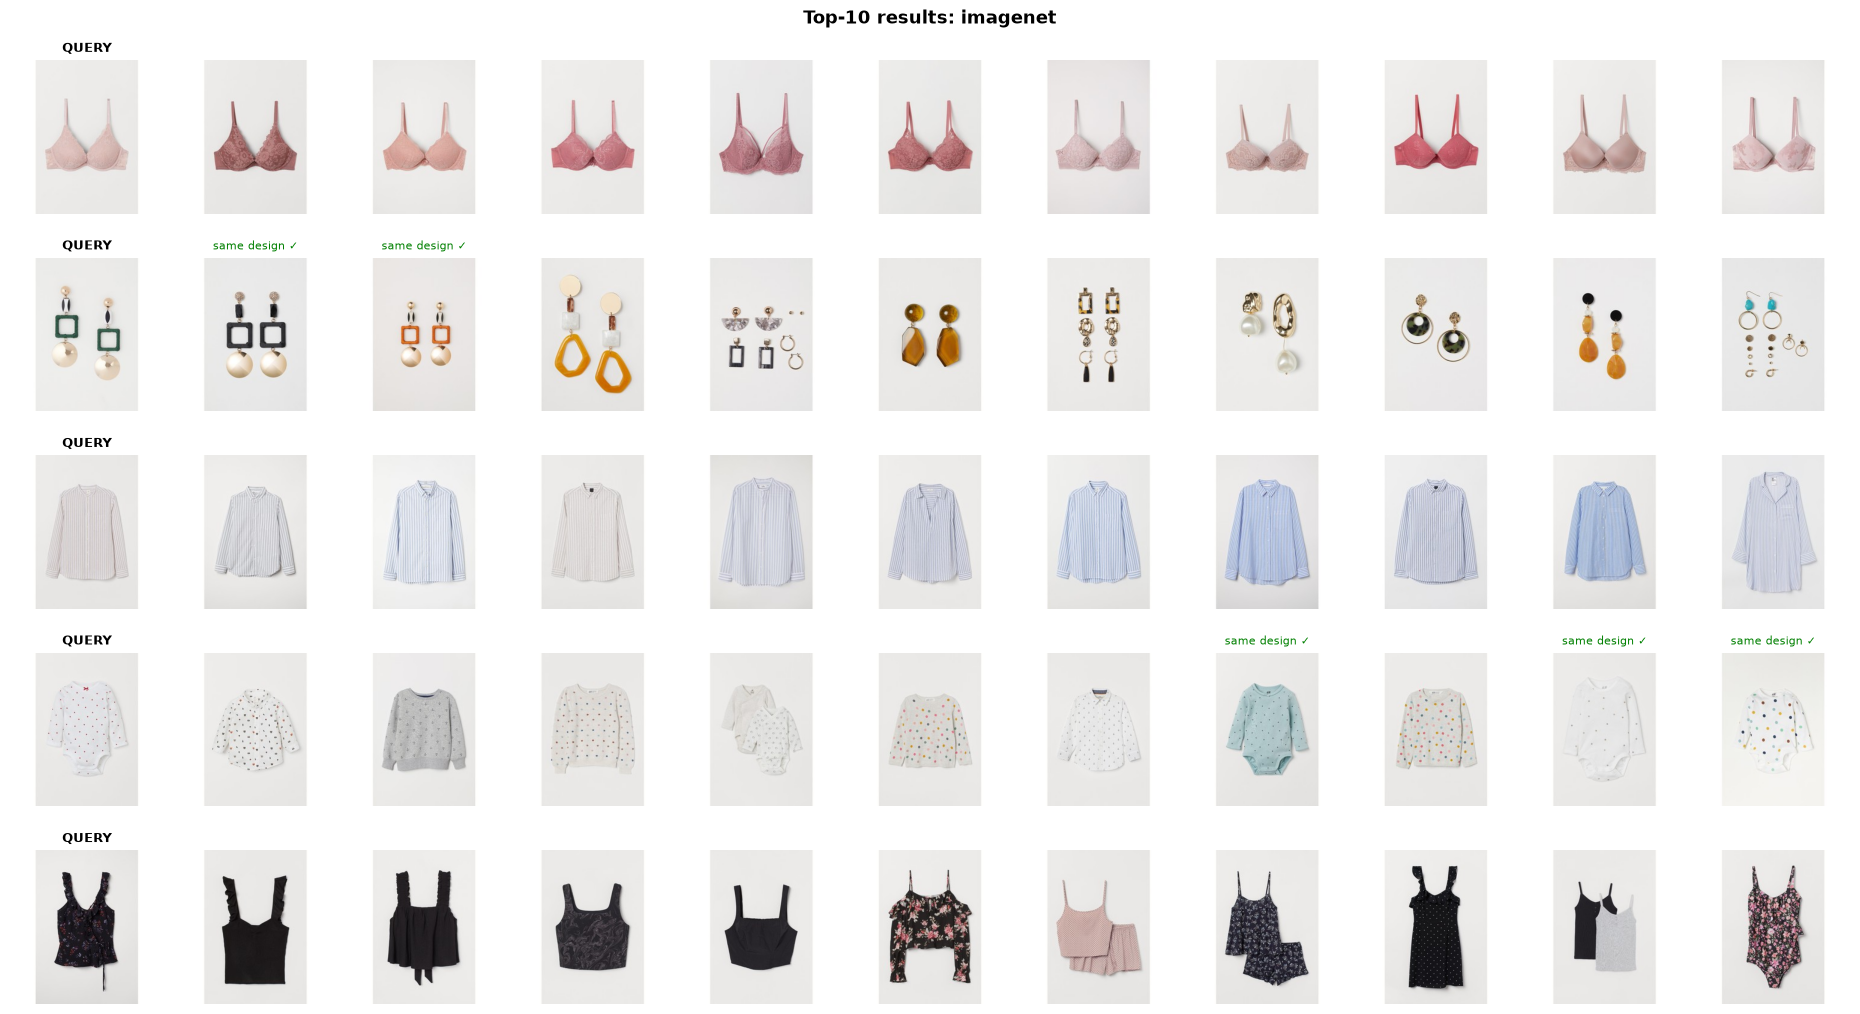

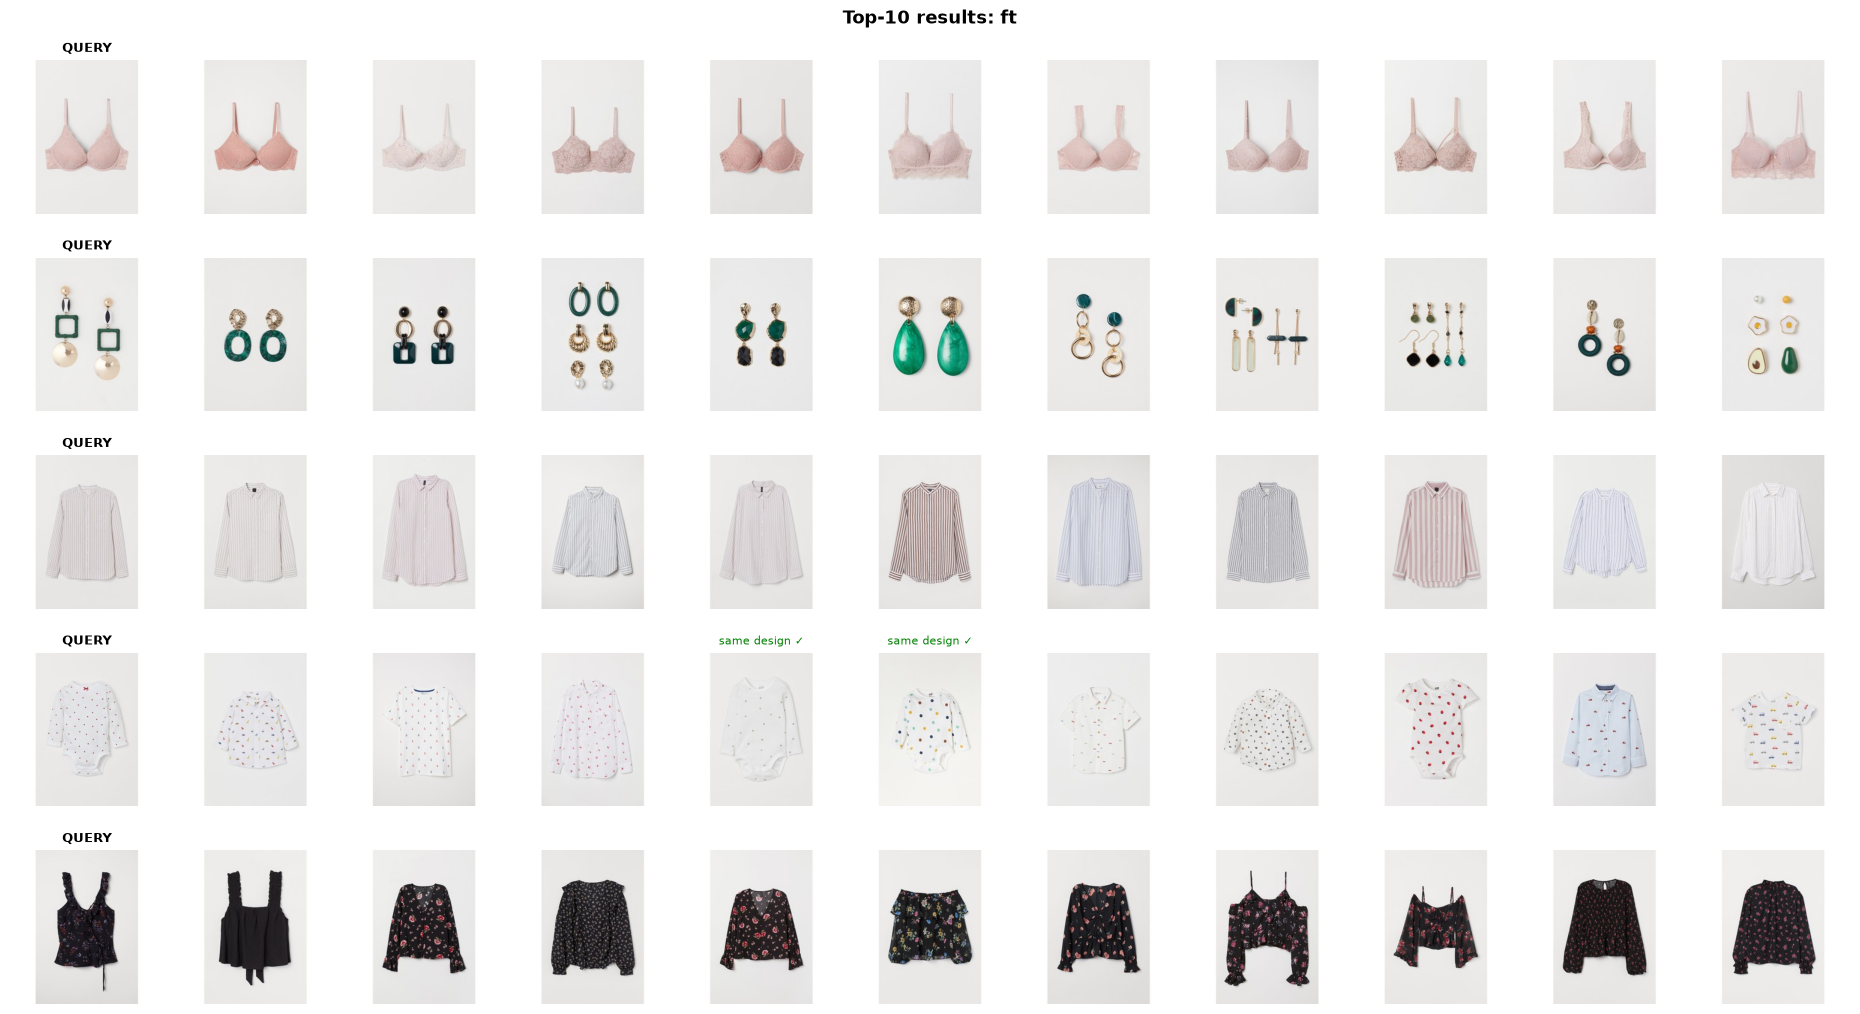

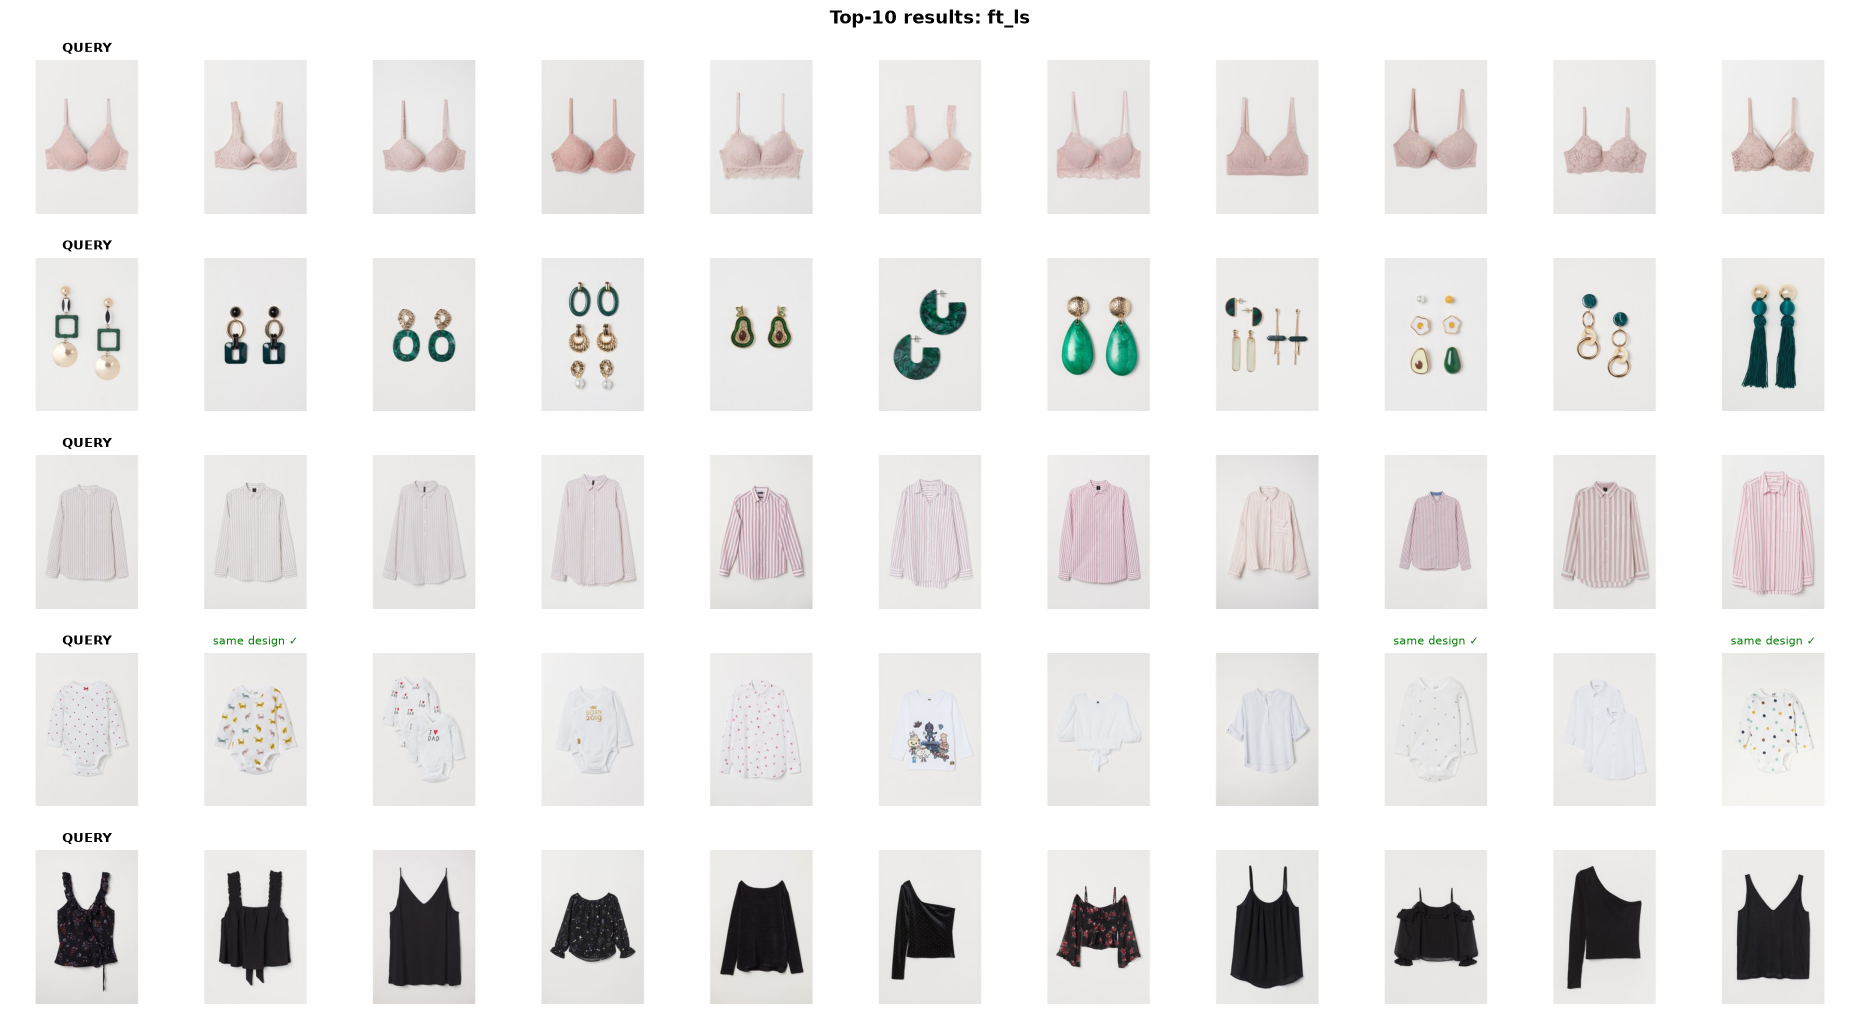

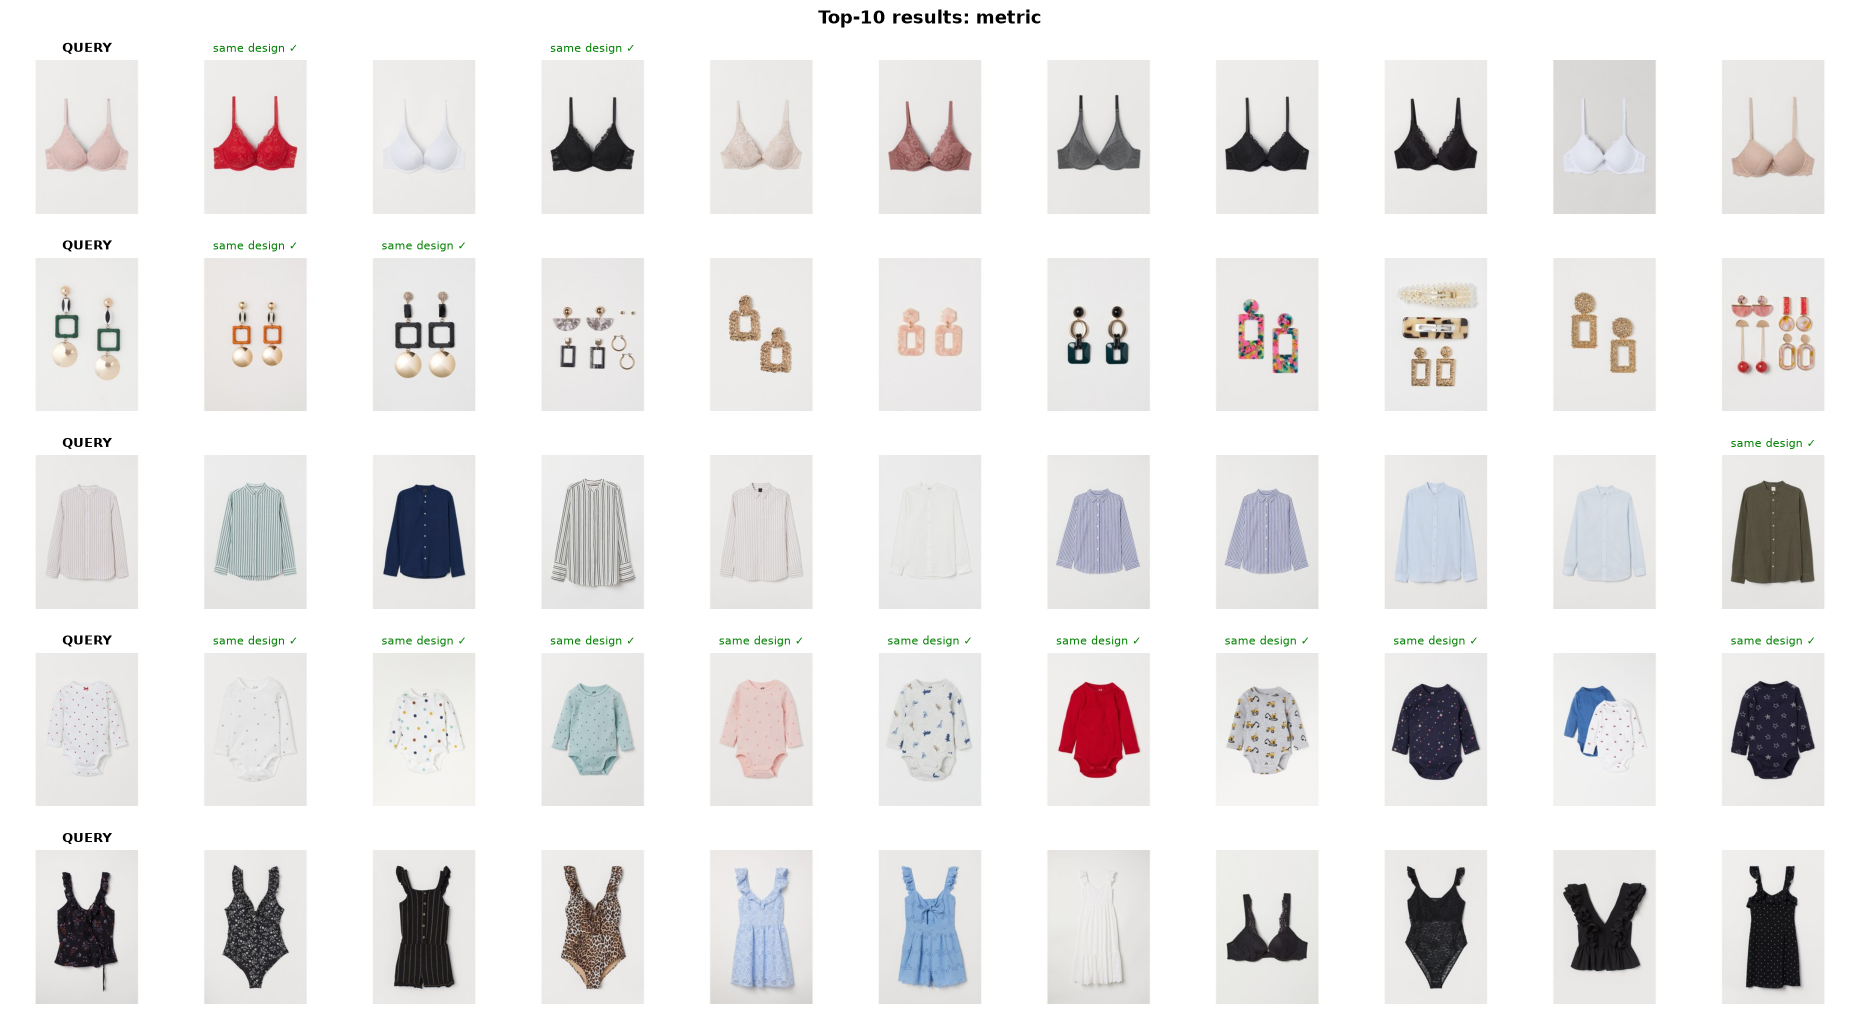

In [4]:
rng = np.random.default_rng(42)
show_q = rng.choice(queries, 5, replace=False)          # 5 random val queries, fixed by the seed
pos = {q: i for i, q in enumerate(queries)}             # query index -> its row in nbr_cache

def gallery(m, qs=show_q, k=10):
    fig, axes = plt.subplots(len(qs), k + 1, figsize=(1.7 * (k + 1), 2.1 * len(qs)))
    for r, q in enumerate(qs):
        for c, j in enumerate([q] + list(nbr_cache[m][pos[q]][:k])):
            ax = axes[r, c]
            ax.imshow(Image.open(IMG_DIR / ids[j][:3] / f"{ids[j]}.jpg"))
            ax.axis("off")
            if c == 0:
                ax.set_title("QUERY", fontsize=9, weight="bold")
            elif code[j] == code[q]:
                ax.set_title("same design ✓", fontsize=8, color="green")
    fig.suptitle(f"Top-10 results: {m}", fontsize=13, weight="bold")
    plt.tight_layout()
    plt.savefig(f"../reports/figures/search_{m}.png", dpi=110)
    plt.show()

for m in MODELS:
    gallery(m)

In [5]:
def hybrid_search(alpha, m_design="imagenet", m_colour="ft_ls", k=20):
    Xd = data[m_design]["emb"].float().numpy() * np.sqrt(alpha)
    Xc = data[m_colour]["emb"].float().numpy() * np.sqrt(1 - alpha)
    X = np.hstack([Xd, Xc])                      # dot product of two rows = α·cos_design + (1−α)·cos_colour
    index = faiss.IndexFlatIP(X.shape[1])
    index.add(X)
    _, nbrs = index.search(X[queries], k + 1)
    keep = nbrs != queries[:, None]
    return np.array([row[ok][:k] for row, ok in zip(nbrs, keep)])

def score(nbrs):
    same = code[nbrs] == code[queries][:, None]
    return {"Recall@1": same[:, :1].any(axis=1).mean(),
            "Recall@10": same[:, :10].any(axis=1).mean(),
            "group match@10": (group[nbrs[:, :10]] == group[queries][:, None]).mean(),
            "colour match@10": (colour[nbrs[:, :10]] == colour[queries][:, None]).mean()}

hyb = {}
for design in ["imagenet", "metric"]:                 # old design half vs the ArcFace-trained one
    for a in [0, 0.25, 0.5, 0.75, 1]:
        nbrs = hybrid_search(a, m_design=design)
        nbr_cache[f"hybrid_{design}_{a}"] = nbrs
        hyb[(design, a)] = score(nbrs)

pd.DataFrame(hyb).T.rename_axis(["design half", "alpha"]).round(3)

Recall@1  Recall@10  group match@10  colour match@10
design half alpha                                                      
imagenet    0.00      0.061      0.159           0.930            0.782
            0.25      0.072      0.185           0.930            0.775
            0.50      0.081      0.215           0.927            0.759
            0.75      0.097      0.261           0.918            0.718
            1.00      0.141      0.360           0.875            0.461
metric      0.00      0.061      0.159           0.930            0.782
            0.25      0.118      0.284           0.932            0.763
            0.50      0.194      0.491           0.935            0.692
            0.75      0.368      0.746           0.935            0.492
            1.00      0.500      0.799           0.914            0.242

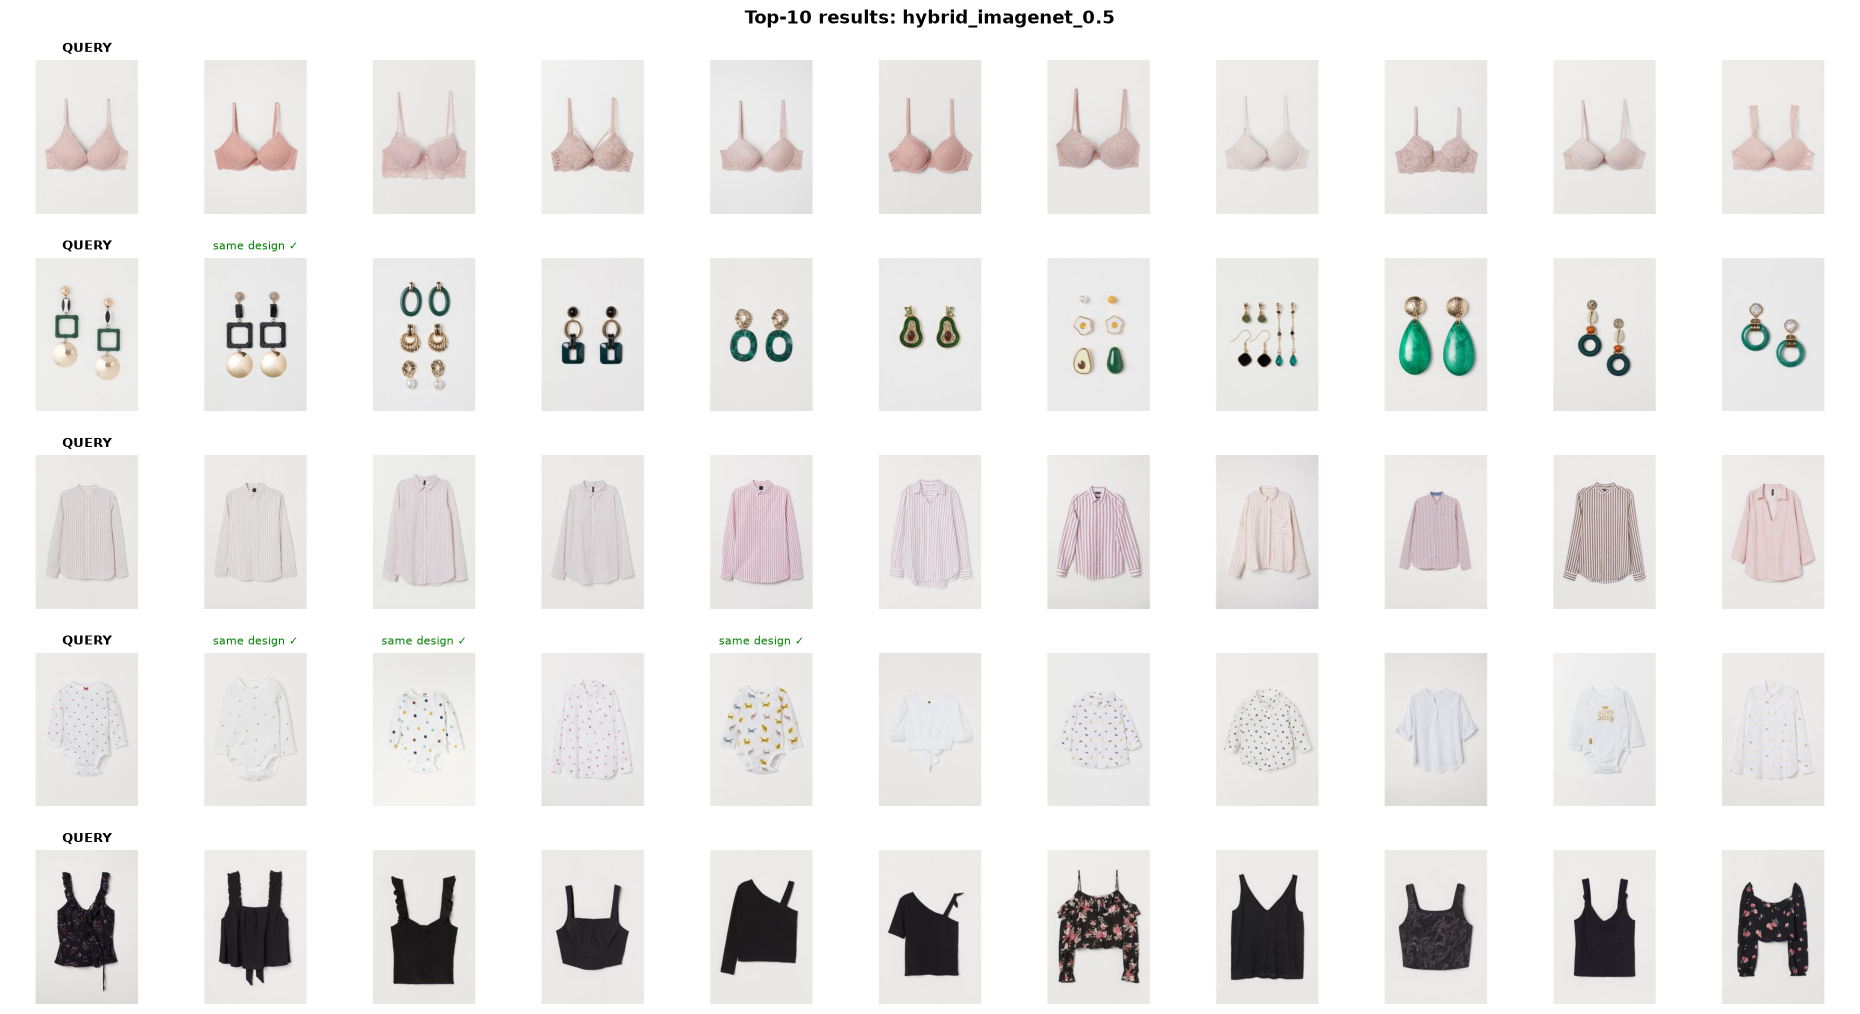

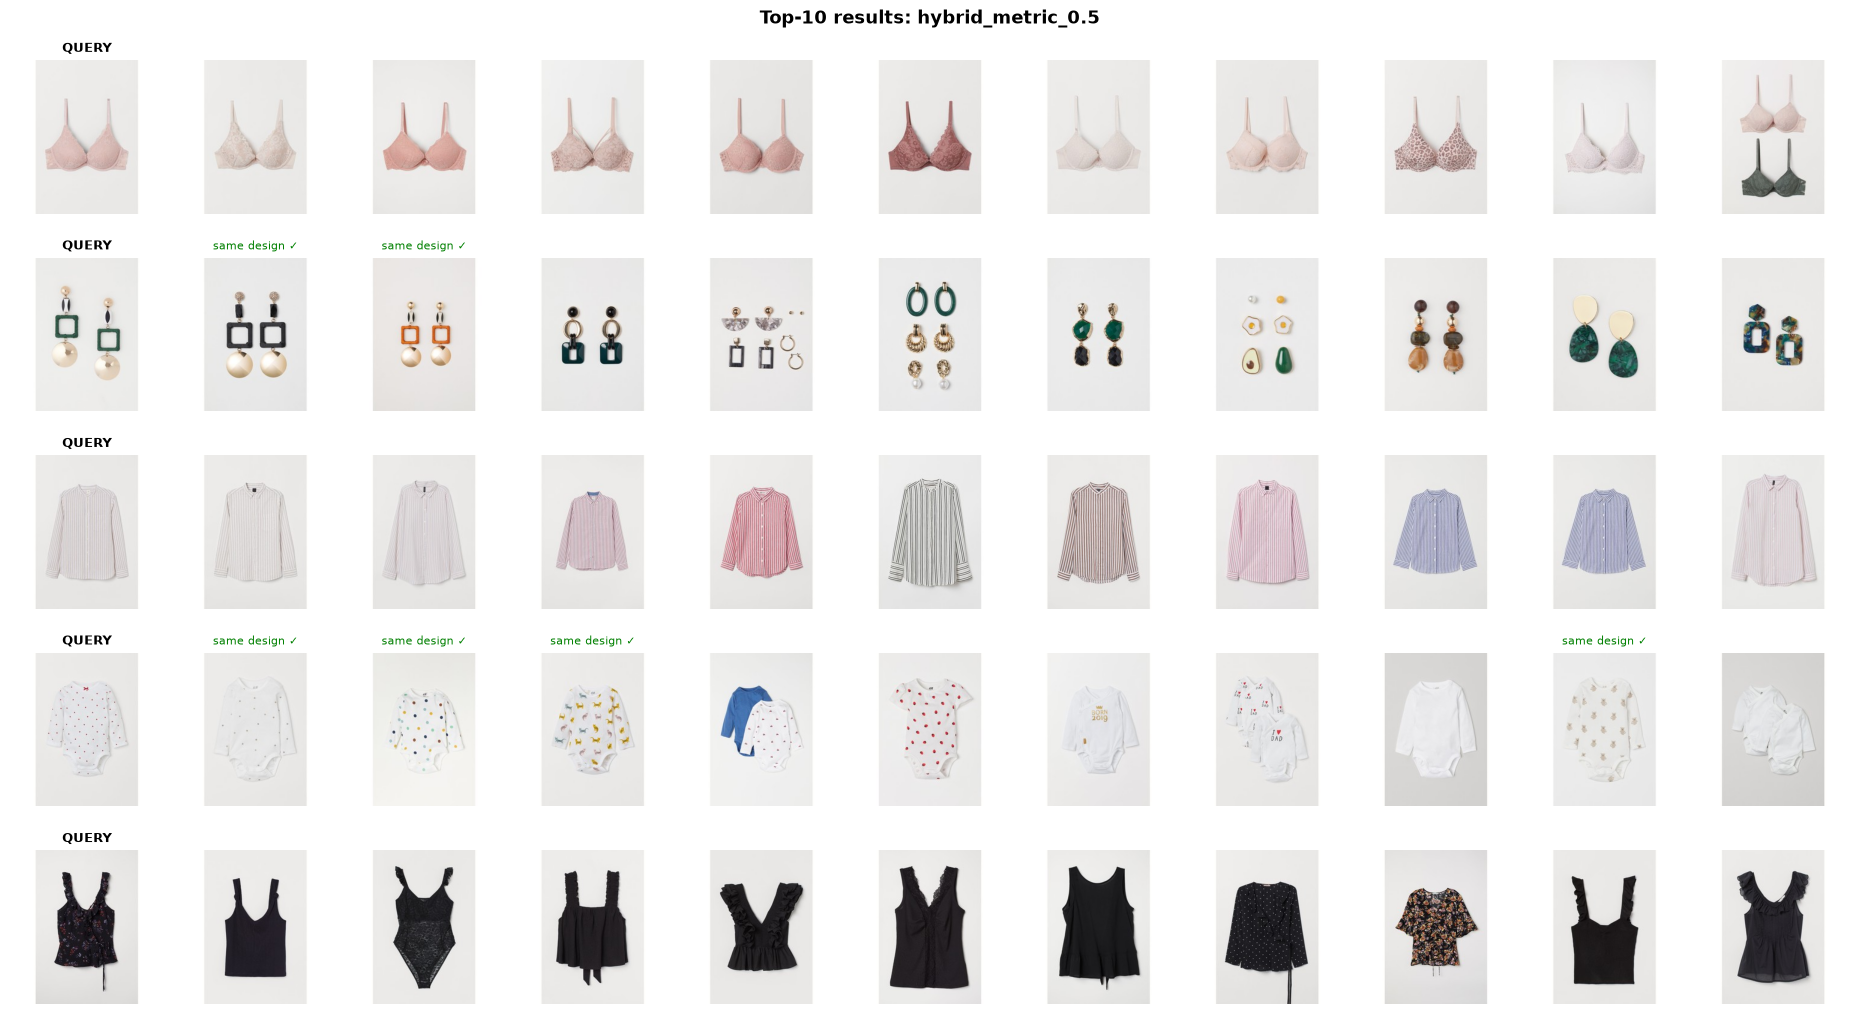

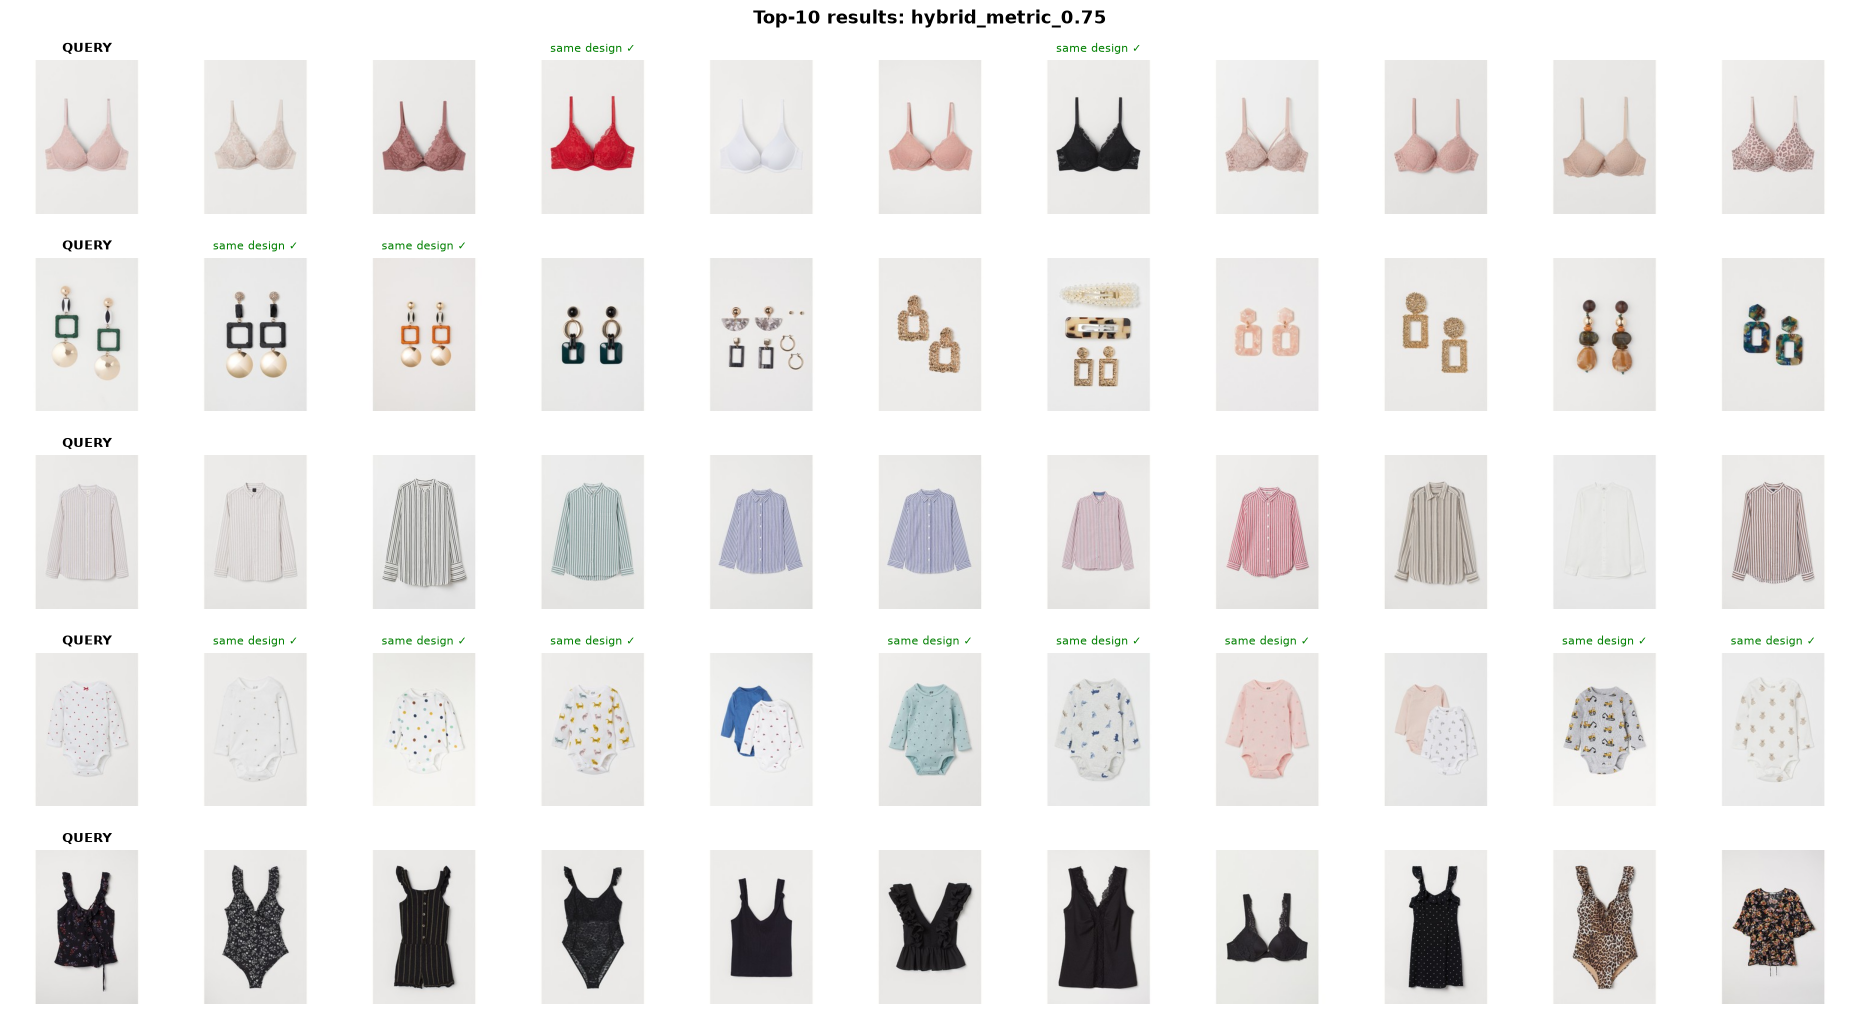

In [6]:
gallery("hybrid_imagenet_0.5")
gallery("hybrid_metric_0.5")
gallery("hybrid_metric_0.75")